# Treino GRPO: Qwen3-1.7B no GSM8K

Treina o Qwen3-1.7B com GRPO (LoRA) para resolver problemas do GSM8K com respostas curtas, sem o modo de pensar, avalia antes e depois no teste completo (1.319 questões) e publica no Hugging Face.

**Configuração do Kaggle (Session options):** GPU T4 x2, Internet On, Persistence: Files only.

**Secret obrigatório:** em *Add-ons → Secrets*, um secret chamado `HF_TOKEN` com o token de escrita do Hugging Face, com a caixinha marcada para este notebook.

**Como rodar, em duas etapas:**
1. Com `SMOKE_TEST = True`, clique em *Run All* (modo interativo). É um teste de uns 10 a 15 minutos: 3 passos de treino, 32 questões, confere o token e não envia nada.
2. Se tudo passar, mude para `SMOKE_TEST = False`, desligue a sessão e clique em **Save Version → Save & Run All**. Roda em segundo plano, com a aba fechada. O treino tem um limite de tempo para a execução inteira caber nas 12 h do Kaggle.

O modelo vai para um repositório **privado**. Você revisa o model card e só depois deixa público.

In [1]:
!pip install -q unsloth

## Configuração

In [2]:
import os, re, json, time, random, math, dataclasses

SMOKE_TEST = False  # True = teste rápido sem envio. Depois: False + Save Version.

HF_USER = "felipedutrain"
REPO_ID = f"{HF_USER}/qwen3-1.7b-gsm8k-grpo"
MODEL_NAME = "Qwen/Qwen3-1.7B"

SEED = 42
MAX_SEQ_LEN = 1024
MAX_PROMPT_LEN = 256
MAX_COMPLETION_LEN = 320
N_SUBSET = 200          # as 200 primeiras questões do teste embaralhado = subconjunto do piloto
EVAL_BATCH = 32

MAX_STEPS = 400
TRAIN_BUDGET_H = 6.0    # o treino para sozinho depois disso e segue para avaliação e envio
PROMPTS_PER_STEP = 4
NUM_GENERATIONS = 8
LEARNING_RATE = 5e-6
WARMUP_STEPS = 10
LORA_R = 16
FORMAT_REWARD = 1.0     # era 0,5 no piloto
LENGTH_PENALTY = 0.0
OUT_DIR = "/kaggle/working"

if SMOKE_TEST:
    MAX_STEPS = 3
    TRAIN_BUDGET_H = 0.25

RUN_START = time.time()
random.seed(SEED)
print("SMOKE_TEST =", SMOKE_TEST)

SMOKE_TEST = False


In [3]:
# Confere o token do Hugging Face já no início (sem enviar nada)
from kaggle_secrets import UserSecretsClient
from huggingface_hub import HfApi

HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
api = HfApi(token=HF_TOKEN)
me = api.whoami()["name"]
assert me == HF_USER, f"O token é da conta {me}, não de {HF_USER}"
os.environ["HF_TOKEN"] = HF_TOKEN
print("Token OK para", me)

Token OK para felipedutrain


In [4]:
import unsloth
import torch, trl, transformers, peft, datasets
from unsloth import FastLanguageModel

VERSIONS = {m.__name__: m.__version__ for m in (unsloth, trl, transformers, peft, datasets, torch)}
GPU_NAME = torch.cuda.get_device_name(0)
print("GPU:", GPU_NAME)
for k, v in VERSIONS.items():
    print(f"{k:>13}: {v}")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
GPU: Tesla T4
      unsloth: 2026.10.11
          trl: 1.15.0
 transformers: 5.16.1
         peft: 0.20.0
     datasets: 4.8.5
        torch: 2.11.0+cu128


## Modelo com LoRA

In [5]:
t0 = time.time()
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL_NAME,
    max_seq_length=MAX_SEQ_LEN,
    load_in_4bit=False,
    fast_inference=False,
)
model = FastLanguageModel.get_peft_model(
    model,
    r=LORA_R,
    lora_alpha=2 * LORA_R,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                    "gate_proj", "up_proj", "down_proj"],
    use_gradient_checkpointing="unsloth",
    random_state=SEED,
)
print(f"Carregado em {time.time() - t0:.0f} s")

==((====))==  Unsloth 2026.10.11: Fast Qwen3 patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Unsloth: Not splitting across GPUs; the model fits on cuda:0 with room to train. Pass device_map = "unsloth_balanced" to split it anyway.


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Unsloth 2026.10.11 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Unsloth: compiling each transformer block as one region (Qwen3DecoderLayer).
Carregado em 45 s


## Dados: GSM8K

In [6]:
from datasets import load_dataset

SYSTEM = ("Solve the math problem. Reason briefly, step by step. "
          "On the last line, write only the final answer as: #### <number>")

def build_prompt(question):
    msgs = [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": question}]
    return tokenizer.apply_chat_template(
        msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)

def gold(answer_text):
    return answer_text.split("####")[-1].strip().replace(",", "")

ds = load_dataset("openai/gsm8k", "main")

train = ds["train"].shuffle(seed=SEED).map(
    lambda x: {"prompt": build_prompt(x["question"]), "answer": gold(x["answer"])})
train = train.remove_columns([c for c in train.column_names if c not in ("prompt", "answer")])
train = train.filter(
    lambda x: len(tokenizer(x["prompt"], add_special_tokens=False).input_ids) <= MAX_PROMPT_LEN)

test = ds["test"].shuffle(seed=SEED)   # mesma ordem do piloto: as 200 primeiras são o subconjunto
eval_rows = [{"idx": i, "question": q, "prompt": build_prompt(q), "answer": gold(a)}
             for i, (q, a) in enumerate(zip(test["question"], test["answer"]))]
if SMOKE_TEST:
    eval_rows = eval_rows[:32]
print(f"Treino: {len(train)} | Avaliação: {len(eval_rows)}")

README.md:   0%|          | 0.00/7.93k [00:00<?, ?B/s]

main/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.31MB            

main/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

main/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  419kB            

main/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

Map:   0%|          | 0/7473 [00:00<?, ? examples/s]

Filter:   0%|          | 0/7473 [00:00<?, ? examples/s]

Treino: 7472 | Avaliação: 1319


## Extração, recompensas e estatística

In [7]:
NUM = r"-?\d[\d,]*\.?\d*"

def to_float(s):
    if s is None:
        return None
    try:
        return float(str(s).replace(",", "").rstrip("."))
    except ValueError:
        return None

def extract_strict(text):
    m = re.findall(r"####\s*\$?\s*(" + NUM + ")", text)
    return to_float(m[-1]) if m else None

def extract_flex(text):
    v = extract_strict(text)
    if v is not None:
        return v
    m = re.findall(NUM, text)
    return to_float(m[-1]) if m else None

def same(a, b):
    return a is not None and b is not None and abs(a - b) < 1e-6

def text_of(c):
    return c if isinstance(c, str) else c[0]["content"]

def correctness_reward(prompts, completions, answer, **kwargs):
    return [2.0 if same(extract_flex(text_of(c)), to_float(a)) else 0.0
            for c, a in zip(completions, answer)]

def format_reward(completions, **kwargs):
    out = []
    for c in completions:
        lines = text_of(c).strip().splitlines()
        last = lines[-1].strip() if lines else ""
        ok = re.fullmatch(r"####\s*\$?\s*" + NUM + r"\s*\.?", last) is not None
        out.append(FORMAT_REWARD if ok else 0.0)
    return out

def length_reward(completions, answer, **kwargs):
    if LENGTH_PENALTY == 0:
        return [0.0] * len(completions)
    out = []
    for c, a in zip(completions, answer):
        t = text_of(c)
        n = len(tokenizer(t, add_special_tokens=False).input_ids)
        ok = same(extract_flex(t), to_float(a))
        out.append(-LENGTH_PENALTY * min(n, MAX_COMPLETION_LEN) / MAX_COMPLETION_LEN if ok else 0.0)
    return out

def wilson(p, n, z=1.96):
    if n == 0:
        return (float("nan"), float("nan"))
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)

def mcnemar_exact(a_correct, b_correct):
    # teste pareado: mesmas questões, antes x depois
    b = sum(1 for x, y in zip(a_correct, b_correct) if x and not y)
    c = sum(1 for x, y in zip(a_correct, b_correct) if y and not x)
    n = b + c
    if n == 0:
        return b, c, 1.0
    k = min(b, c)
    p = 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n
    return b, c, min(1.0, p)

_c = ["3 boxes * 12 = 36, 36 - 7 = 29\n#### 29", "The answer is 29.",
      "So she has $1,250.\n#### $1,250", "#### 30"]
_a = ["29", "29", "1250", "29"]
assert correctness_reward(None, _c, _a) == [2.0, 2.0, 2.0, 0.0]
assert format_reward(_c) == [FORMAT_REWARD, 0.0, FORMAT_REWARD, FORMAT_REWARD]
assert mcnemar_exact([1, 1, 0, 0], [1, 0, 1, 1])[:2] == (1, 2)
print("Funções OK")

Funções OK


## Avaliação (mesmo protocolo antes e depois)

In [8]:
import pandas as pd

def evaluate(rows, tag):
    FastLanguageModel.for_inference(model)
    old_side = tokenizer.padding_side
    tokenizer.padding_side = "left"
    order = sorted(rows, key=lambda r: len(r["prompt"]))  # menos padding, mais rápido
    recs, t0 = [], time.time()
    for i in range(0, len(order), EVAL_BATCH):
        batch = order[i:i + EVAL_BATCH]
        enc = tokenizer([r["prompt"] for r in batch], return_tensors="pt",
                        padding=True, add_special_tokens=False).to("cuda")
        with torch.no_grad():
            out = model.generate(**enc, max_new_tokens=MAX_COMPLETION_LEN,
                                 do_sample=False, pad_token_id=tokenizer.pad_token_id)
        gen = out[:, enc["input_ids"].shape[1]:]
        for r, g in zip(batch, gen):
            ids = [t for t in g.tolist() if t != tokenizer.pad_token_id]
            text = tokenizer.decode(ids, skip_special_tokens=True)
            gold_v = to_float(r["answer"])
            recs.append({
                "idx": r["idx"], "question": r["question"], "gold": r["answer"],
                "output": text, "n_tokens": len(ids),
                "truncated": len(ids) >= MAX_COMPLETION_LEN,
                "correct_strict": same(extract_strict(text), gold_v),
                "correct_flex": same(extract_flex(text), gold_v),
            })
        if (i // EVAL_BATCH) % 10 == 0:
            print(f"  {tag}: {min(i + EVAL_BATCH, len(order))}/{len(order)} em {time.time() - t0:.0f} s")
    tokenizer.padding_side = old_side
    FastLanguageModel.for_training(model)
    df = pd.DataFrame(recs).sort_values("idx").reset_index(drop=True)
    df.to_csv(f"{OUT_DIR}/eval_{tag}.csv", index=False)
    print(f"{tag}: {len(df)} questões em {time.time() - t0:.0f} s")
    return df

def summarize(df, tag):
    rows = []
    for scope, d in (("teste completo", df), (f"subconjunto {N_SUBSET}", df[df.idx < N_SUBSET])):
        n = len(d)
        ps, pf = d.correct_strict.mean(), d.correct_flex.mean()
        lo, hi = wilson(pf, n)
        rows.append({"modelo": tag, "escopo": scope, "n": n,
                     "acc_strict": round(ps, 4), "acc_flex": round(pf, 4),
                     "flex_ic95": f"{lo:.3f}-{hi:.3f}",
                     "mean_tokens": round(d.n_tokens.mean(), 1),
                     "truncated_rate": round(d.truncated.mean(), 4)})
    return rows

base_df = evaluate(eval_rows, "base")
pd.DataFrame(summarize(base_df, "base"))

Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  base: 32/1319 em 42 s


Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

  base: 352/1319 em 644 s


Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

  base: 672/1319 em 1395 s


Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

  base: 992/1319 em 2195 s


Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

  base: 1312/1319 em 3006 s
base: 1319 questões em 3027 s


,modelo,escopo,n,acc_strict,acc_flex,flex_ic95,mean_tokens,truncated_rate
0,base,teste completo,1319,0.0288,0.7657,0.742-0.788,149.6,0.0303
1,base,subconjunto 200,200,0.0350,0.7850,0.723-0.836,149.7,0.0200


## Treino GRPO

In [9]:
from trl import GRPOConfig, GRPOTrainer
from transformers import TrainerCallback

class TimeBudget(TrainerCallback):
    def __init__(self, hours):
        self.deadline = time.time() + hours * 3600
    def on_step_end(self, args, state, control, **kwargs):
        if time.time() > self.deadline:
            print(f"Limite de {TRAIN_BUDGET_H} h atingido no passo {state.global_step}; encerrando o treino.")
            control.should_training_stop = True
            control.should_save = True
        return control

major, _ = torch.cuda.get_device_capability()
cfg = dict(
    output_dir=f"{OUT_DIR}/checkpoints",
    learning_rate=LEARNING_RATE,
    lr_scheduler_type="cosine",
    warmup_steps=WARMUP_STEPS,
    per_device_train_batch_size=NUM_GENERATIONS,      # 8 respostas de 1 pergunta por micro-lote
    gradient_accumulation_steps=PROMPTS_PER_STEP,     # 4 perguntas por passo
    num_generations=NUM_GENERATIONS,
    max_completion_length=MAX_COMPLETION_LEN,
    max_steps=MAX_STEPS,
    logging_steps=1,
    save_steps=50,
    save_total_limit=2,
    report_to="none",
    seed=SEED,
    bf16=major >= 8,
    fp16=major < 8,
    optim="adamw_torch",
    max_grad_norm=0.1,
)
known = {f.name for f in dataclasses.fields(GRPOConfig)}
dropped = [k for k in cfg if k not in known]
if dropped:
    print("Ignorado nesta versão do TRL:", dropped)
args = GRPOConfig(**{k: v for k, v in cfg.items() if k in known})

trainer = GRPOTrainer(
    model=model,
    processing_class=tokenizer,
    reward_funcs=[correctness_reward, format_reward, length_reward],
    args=args,
    train_dataset=train,
    callbacks=[TimeBudget(TRAIN_BUDGET_H)],
)
TRAIN_INFO = {"loss_type": getattr(args, "loss_type", None), "beta": getattr(args, "beta", None)}
print("GRPO:", TRAIN_INFO)

t0 = time.time()
trainer.train()
TRAIN_INFO.update({
    "steps_done": trainer.state.global_step,
    "prompts_seen": trainer.state.global_step * PROMPTS_PER_STEP,
    "train_hours": round((time.time() - t0) / 3600, 2),
})
print(TRAIN_INFO)

Unsloth: GRPO now defaults to TRL's loss_type = 'dapo' with beta = 0.0. Set loss_type = 'bnpo', beta = 0.001 for Unsloth's previous default.
GRPO: {'loss_type': 'dapo', 'beta': 0.0}


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 7,472 | Num Epochs = 1 | Total steps = 400
O^O/ \_/ \    Batch size per device = 8 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (8 x 4 x 1) = 32
 "-____-"     Trainable parameters = 17,432,576 of 1,738,007,552 (1.00% trained)
Passing `generation_config` together with generation-related arguments=({'pad_token_id', 'cache_implementation'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedenc

Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,reward,reward_std,completions / mean_length,completions / min_length,completions / max_length,completions / clipped_ratio,completions / mean_terminated_length,completions / min_terminated_length,completions / max_terminated_length,kl,rewards / correctness_reward / mean,rewards / correctness_reward / std,rewards / format_reward / mean,rewards / format_reward / std,rewards / length_reward / mean,rewards / length_reward / std
1,-0.001088,1.468750,1.015505,163.718750,116.000000,232.000000,0.000000,163.718750,116.000000,232.000000,0.000000,1.312500,0.965117,0.156250,0.368902,0.000000,0.000000
2,0.011522,1.562500,0.948258,116.750000,62.000000,225.000000,0.000000,116.750000,62.000000,225.000000,0.000000,1.500000,0.879883,0.062500,0.245935,0.000000,0.000000
3,-0.027432,1.812500,0.644455,109.437500,57.000000,183.000000,0.000000,109.437500,57.000000,183.000000,0.000000,1.750000,0.672022,0.062500,0.245935,0.000000,0.000000
4,0.017279,1.906250,0.530330,152.718750,80.000000,236.000000,0.000000,152.718750,80.000000,236.000000,0.000000,1.875000,0.491869,0.031250,0.176777,0.000000,0.000000
5,-0.064756,1.281250,0.958304,186.812500,113.000000,299.000000,0.000000,186.812500,113.000000,299.000000,0.000000,1.250000,0.983739,0.031250,0.176777,0.000000,0.000000
6,0.054244,2.000000,0.439941,154.562500,78.000000,246.000000,0.000000,154.562500,78.000000,246.000000,0.000000,1.937500,0.353553,0.062500,0.245935,0.000000,0.000000
7,-0.002985,2.093750,0.296145,135.687500,97.000000,169.000000,0.000000,135.687500,97.000000,169.000000,0.000000,2.000000,0.000000,0.093750,0.296145,0.000000,0.000000
8,-0.016202,1.406250,0.979117,167.281250,56.000000,320.000000,0.125000,145.464294,56.000000,314.000000,0.000000,1.375000,0.941858,0.031250,0.176777,0.000000,0.000000
9,0.014223,1.531250,0.915260,93.968750,56.000000,134.000000,0.000000,93.968750,56.000000,134.000000,0.000000,1.500000,0.879883,0.031250,0.176777,0.000000,0.000000
10,-0.005957,1.812500,0.692704,115.468750,52.000000,242.000000,0.000000,115.468750,52.000000,242.000000,0.000000,1.687500,0.737804,0.125000,0.336011,0.000000,0.000000


Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Limite de 6.0 h atingido no passo 357; encerrando o treino.


Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/checkpoints/checkpoint-357/tokenizer_config.json.


{'loss_type': 'dapo', 'beta': 0.0, 'steps_done': 357, 'prompts_seen': 1428, 'train_hours': 6.02}


In [10]:
# Seguro: salva e envia o adaptador LoRA logo depois do treino, antes de qualquer outra coisa
model.save_pretrained(f"{OUT_DIR}/lora")
tokenizer.save_pretrained(f"{OUT_DIR}/lora")
if not SMOKE_TEST:
    api.create_repo(REPO_ID, private=True, exist_ok=True)
    api.upload_folder(folder_path=f"{OUT_DIR}/lora", repo_id=REPO_ID, path_in_repo="lora",
                      commit_message="LoRA adapter")
    print("LoRA enviado para", REPO_ID)

Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/lora/tokenizer_config.json.


LoRA enviado para felipedutrain/qwen3-1.7b-gsm8k-grpo


## Avaliação depois do treino

In [11]:
after_df = evaluate(eval_rows, "grpo")
summary = pd.DataFrame(summarize(base_df, "base") + summarize(after_df, "grpo"))
summary.to_csv(f"{OUT_DIR}/comparacao.csv", index=False)

STATS = {}
for metric in ("correct_flex", "correct_strict"):
    b, c, p = mcnemar_exact(base_df[metric].tolist(), after_df[metric].tolist())
    STATS[metric] = {"so_base_acerta": b, "so_grpo_acerta": c, "p_mcnemar": p}
print(json.dumps(STATS, indent=2))
summary

Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  grpo: 32/1319 em 50 s


Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

  grpo: 352/1319 em 608 s


Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

  grpo: 672/1319 em 1299 s


Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

  grpo: 992/1319 em 2011 s


Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

  grpo: 1312/1319 em 2772 s
grpo: 1319 questões em 2794 s
{
  "correct_flex": {
    "so_base_acerta": 83,
    "so_grpo_acerta": 79,
    "p_mcnemar": 0.8137534121779036
  },
  "correct_strict": {
    "so_base_acerta": 1,
    "so_grpo_acerta": 963,
    "p_mcnemar": 1.2377743791415416e-287
  }
}


,modelo,escopo,n,acc_strict,acc_flex,flex_ic95,mean_tokens,truncated_rate
0,base,teste completo,1319,0.0288,0.7657,0.742-0.788,149.6,0.0303
1,base,subconjunto 200,200,0.0350,0.7850,0.723-0.836,149.7,0.0200
2,grpo,teste completo,1319,0.7582,0.7627,0.739-0.785,129.2,0.0144
3,grpo,subconjunto 200,200,0.7850,0.7900,0.728-0.841,128.6,0.0100


## Curvas do treino

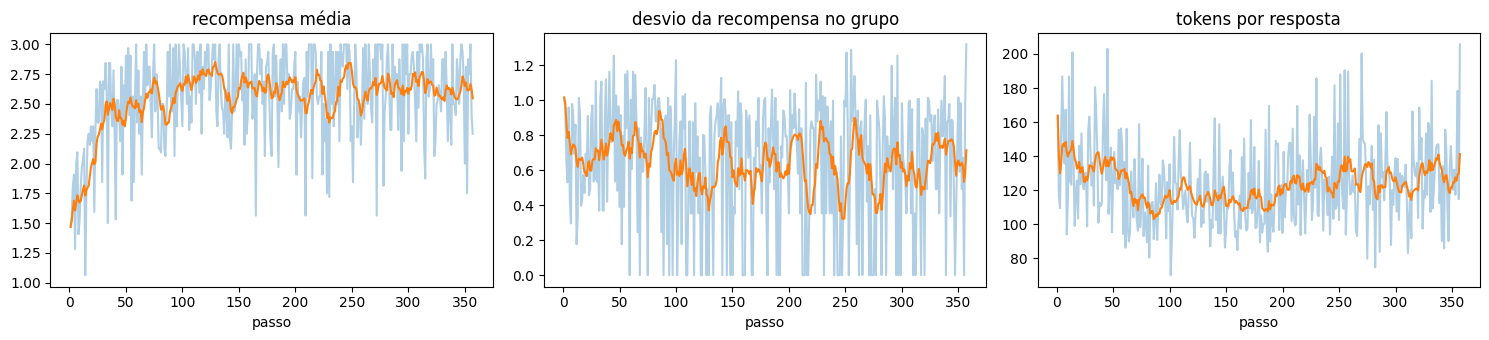

In [12]:
import matplotlib.pyplot as plt

log = pd.DataFrame([h for h in trainer.state.log_history if "reward" in h])
log.to_csv(f"{OUT_DIR}/log_treino.csv", index=False)
len_col = next((c for c in ("completions/mean_length", "completion_length") if c in log.columns), None)
panels = [("reward", "recompensa média"), ("reward_std", "desvio da recompensa no grupo")]
if len_col:
    panels.append((len_col, "tokens por resposta"))
fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 3.5))
for ax, (col, title) in zip(axes, panels):
    ax.plot(log["step"], log[col], alpha=0.35)
    ax.plot(log["step"], log[col].rolling(10, min_periods=1).mean())
    ax.set_title(title); ax.set_xlabel("passo")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/curvas_treino.png", dpi=120)
plt.show()

## Model card e envio

In [13]:
def build_card(summary, stats, info, versions, gpu):
    full = summary[summary.escopo == "teste completo"].set_index("modelo")
    def row(tag, name):
        r = full.loc[tag]
        return (f"| {name} | {r.acc_strict:.1%} | {r.acc_flex:.1%} ({r.flex_ic95}) "
                f"| {r.mean_tokens:.0f} | {r.truncated_rate:.1%} |")
    sf, ss = stats["correct_flex"], stats["correct_strict"]
    vers = ", ".join(f"{k} {v}" for k, v in versions.items())
    return f'''---
base_model: {MODEL_NAME}
license: apache-2.0
datasets:
- openai/gsm8k
language:
- en
pipeline_tag: text-generation
tags:
- qwen3
- grpo
- gsm8k
- math
- reasoning
- lora
- unsloth
- trl
---

# Qwen3-1.7B GSM8K GRPO

{MODEL_NAME} fine-tuned with GRPO (LoRA) on the GSM8K train split to solve grade-school math problems with short answers, in non-thinking mode. Part of a project that runs small LLMs on a PlayStation 4 (AMD Jaguar CPU) with llama.cpp, where every generated token is expensive.

## Results

GSM8K test set, n = {int(full.loc["base"].n)}, greedy decoding, non-thinking mode, at most {MAX_COMPLETION_LEN} new tokens, same prompt and protocol for both models.

| Model | Strict | Flexible (95% CI) | Mean tokens | Truncated |
|---|---|---|---|---|
{row("base", "Qwen3-1.7B (base)")}
{row("grpo", "This model")}

- **Strict:** the last `#### <number>` in the output matches the reference answer.
- **Flexible:** the strict answer if present, otherwise the last number in the output.
- Paired McNemar test (same questions): flexible p = {sf["p_mcnemar"]:.3g} ({sf["so_grpo_acerta"]} questions fixed, {sf["so_base_acerta"]} broken); strict p = {ss["p_mcnemar"]:.3g}.

## Prompt

System prompt used in training and evaluation:

> {SYSTEM}

Use the Qwen3 chat template with `enable_thinking=False`.

## Training

- Method: GRPO with LoRA (r = {LORA_R}, alpha = {2 * LORA_R}, all attention and MLP projections), loss type `{info.get("loss_type")}`, beta = {info.get("beta")}
- Rewards: correctness 2.0 (flexible match), format {FORMAT_REWARD} (last line is `#### <number>`), length penalty {LENGTH_PENALTY}
- {info.get("steps_done")} steps, {PROMPTS_PER_STEP} prompts per step, {NUM_GENERATIONS} completions per prompt ({info.get("prompts_seen")} prompts seen), learning rate {LEARNING_RATE}, cosine schedule, {WARMUP_STEPS} warmup steps
- Hardware: 1x {gpu} (Kaggle), {info.get("train_hours")} h of training
- Software: {vers}

## Limitations

- Single training run with one seed; differences of a few points can be noise, see the confidence intervals and the McNemar test.
- Trained and evaluated only on GSM8K, in English.
- Greedy decoding with a {MAX_COMPLETION_LEN}-token limit; truncated answers count as wrong.

## Repository

LoRA adapter in `lora/`, per-question evaluation outputs in `eval/`. Code and PS4 benchmarks: TODO link to GitHub.
'''

card = build_card(summary, STATS, TRAIN_INFO, VERSIONS, GPU_NAME)
with open(f"{OUT_DIR}/README.md", "w") as f:
    f.write(card)
print(card)

---
base_model: Qwen/Qwen3-1.7B
license: apache-2.0
datasets:
- openai/gsm8k
language:
- en
pipeline_tag: text-generation
tags:
- qwen3
- grpo
- gsm8k
- math
- reasoning
- lora
- unsloth
- trl
---

# Qwen3-1.7B GSM8K GRPO

Qwen/Qwen3-1.7B fine-tuned with GRPO (LoRA) on the GSM8K train split to solve grade-school math problems with short answers, in non-thinking mode. Part of a project that runs small LLMs on a PlayStation 4 (AMD Jaguar CPU) with llama.cpp, where every generated token is expensive.

## Results

GSM8K test set, n = 1319, greedy decoding, non-thinking mode, at most 320 new tokens, same prompt and protocol for both models.

| Model | Strict | Flexible (95% CI) | Mean tokens | Truncated |
|---|---|---|---|---|
| Qwen3-1.7B (base) | 2.9% | 76.6% (0.742-0.788) | 150 | 3.0% |
| This model | 75.8% | 76.3% (0.739-0.785) | 129 | 1.4% |

- **Strict:** the last `#### <number>` in the output matches the reference answer.
- **Flexible:** the strict answer if present, otherwise the la

In [14]:
if SMOKE_TEST:
    print("Teste rápido concluído. Nada foi enviado. Mude SMOKE_TEST para False e use Save Version.")
else:
    t0 = time.time()
    merged = f"{OUT_DIR}/merged"
    model.save_pretrained_merged(merged, tokenizer, save_method="merged_16bit")
    os.replace(f"{OUT_DIR}/README.md", f"{merged}/README.md")
    api.upload_folder(folder_path=merged, repo_id=REPO_ID, commit_message="Merged 16-bit model and model card")
    os.makedirs(f"{OUT_DIR}/eval", exist_ok=True)
    for f in ("eval_base.csv", "eval_grpo.csv", "comparacao.csv", "log_treino.csv", "curvas_treino.png"):
        os.replace(f"{OUT_DIR}/{f}", f"{OUT_DIR}/eval/{f}")
    api.upload_folder(folder_path=f"{OUT_DIR}/eval", repo_id=REPO_ID, path_in_repo="eval",
                      commit_message="Evaluation outputs")
    print(f"Enviado em {time.time() - t0:.0f} s: https://huggingface.co/{REPO_ID} (privado)")

print(f"Tempo total da execução: {(time.time() - RUN_START) / 3600:.2f} h")

Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/merged/tokenizer_config.json.


Found HuggingFace hub cache directory: /root/.cache/huggingface/hub
Checking cache directory for required files...


Unsloth: Copying 1 files from cache to `/kaggle/working/merged`: 100%|██████████| 1/1 [00:02<00:00,  2.11s/it]


Successfully copied all 1 files from cache to `/kaggle/working/merged`
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.


Unsloth: Merging weights into 16bit: 100%|██████████| 1/1 [00:27<00:00, 27.01s/it]


Unsloth: Merge process complete. Saved to `/kaggle/working/merged`
Enviado em 68 s: https://huggingface.co/felipedutrain/qwen3-1.7b-gsm8k-grpo (privado)
Tempo total da execução: 7.69 h


## Depois da execução

1. Abra `https://huggingface.co/felipedutrain/qwen3-1.7b-gsm8k-grpo` (privado) e confira o model card.
2. Os GGUF (Q4_K_M e Q8_0), do modelo treinado e do base, saem pelo mesmo pipeline no Fedora com o llama.cpp, a partir dos pesos enviados aqui.
3. Só depois disso o repositório fica público.